In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib import gridspec
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import xarray as xr
import matplotlib.dates as mdates
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
import xarray as xr
from concurrent.futures import ProcessPoolExecutor
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=1,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='1:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/distributed/node.py:182: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 37311 instead
  warnings.warn(


In [3]:
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/37311/status,
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/37311/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.207:33373,Workers: 0
Dashboard: /node/crhtc99.hpc.ucar.edu/61175/proxy/37311/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [4]:
def leap_adjusted_doy(time):
    doy = time.dt.dayofyear
    is_leap = time.dt.is_leap_year
    after_feb = time.dt.month > 2
    return doy - (is_leap & after_feb).astype(int)

def fourier(period, k, n):
    # Get periods for each fourier
    p = [x/period for x in range(1,k+1)]
    # Create array of ones
    result = np.ones( (n, 2*k+1) )
    # Fill in array with fourier series
    for i in range(k):
        result[:,(2*i)] = [np.sin(2*np.pi*x*p[i]) for x in range(1,n+1)]
        result[:,(2*i+1)] = [np.cos(2*np.pi*x*p[i]) for x in range(1,n+1)]
    return result

################################################################################

def seasonality_removal_worker(data, I, X):    
    # Regress fourier series on data
    B = I.dot(data)
    y_pred = X.dot(B)
    return data - y_pred

################################################################################

def seasonality_removal(data, k):
    n=len(data)
    # Create fourier series to regress
    fX = fourier(365, k=k, n=n)
    B = np.linalg.inv(fX.T.dot(fX)).dot(fX.T)
    # Stack data and apply worker function to each gridcell
    data_stack = data.stack(gridcell=('lat', 'lon'))
    result = data_stack.groupby('gridcell').map(seasonality_removal_worker, I = B, X = fX).unstack('gridcell')
    return result

################################################################################

def seasonality_removal_vals(data, k):
    n=len(data)
    # Create fourier series to regress
    fX = fourier(365, k=k, n=n)
    B = np.linalg.inv(fX.T.dot(fX)).dot(fX.T)
    # reshape data to apply worker function to each gridcell
    data_reshape = data.reshape((data.shape[0], data.shape[1] * data.shape[2]))
    result_reshape = np.apply_along_axis(seasonality_removal_worker, 0, data_reshape, I = B, X = fX)
    result = result_reshape.reshape((data.shape[0], data.shape[1], data.shape[2]))
    return result

In [5]:
event_windows = {
    'E1': ('2024-05-25', '2024-06-01'),
    'E2': ('2024-06-10', '2024-06-20'),
}

In [6]:
ds = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/Predicted_RZSM_ENTIRE_INDIA_NETCDF/RZSM_*.nc')
ds = ds.sel(time=~((ds.time.dt.month == 2) & (ds.time.dt.day == 29)))
ds = ds.assign_coords(doy=("time", leap_adjusted_doy(ds.time).values))
ds_subset = ds['rzsm'].sel(lat=slice(22,30),lon=slice(75,85))
ds_subset = dask.compute(ds_subset)[0]
ds_anom = seasonality_removal_vals(ds_subset.values,3)
da_anom = xr.DataArray(ds_anom,dims=ds_subset.dims,coords=ds_subset.coords)
da_anom_56 = da_anom.sel(time=da_anom.time.dt.month.isin([5,6,7]))
df_mean = da_anom_56.mean(dim=['lat','lon'])
df_mean_p10 = df_mean.groupby('doy').quantile(0.10)

In [7]:
ds_gleam = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/GLEAM/SMrz*.nc')
ds_gleam = ds_gleam.sel(time=~((ds_gleam.time.dt.month == 2) & (ds_gleam.time.dt.day == 29)))
ds_gleam = ds_gleam.assign_coords(doy=("time", leap_adjusted_doy(ds_gleam.time).values))
ds_gleam_subset = ds_gleam['SMrz'].sel(lat=slice(30,22),lon=slice(75,85))
ds_gleam_subset = dask.compute(ds_gleam_subset)[0]
ds_gleam_anom = seasonality_removal_vals(ds_gleam_subset.values,3)
da_gleam_anom = xr.DataArray(ds_gleam_anom,dims=ds_gleam_subset.dims,coords=ds_gleam_subset.coords)
da_gleam_anom_56 = da_gleam_anom.sel(time=da_gleam_anom.time.dt.month.isin([5,6,7]))
df_gleam_mean = da_gleam_anom_56.mean(dim=['lat','lon'])
df_gleam_mean_p10 = df_gleam_mean.groupby('doy').quantile(0.10)

In [8]:
ds_gleam_s = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/GLEAM/SMs*.nc')
ds_gleam_s = ds_gleam_s.sel(time=~((ds_gleam_s.time.dt.month == 2) & (ds_gleam_s.time.dt.day == 29)))
ds_gleam_s = ds_gleam_s.assign_coords(doy=("time", leap_adjusted_doy(ds_gleam_s.time).values))
ds_gleam_s_subset = ds_gleam_s['SMs'].sel(lat=slice(30,22),lon=slice(75,85))
ds_gleam_s_subset = dask.compute(ds_gleam_s_subset)[0]
ds_gleam_s_anom = seasonality_removal_vals(ds_gleam_s_subset.values,3)
da_gleam_s_anom = xr.DataArray(ds_gleam_s_anom,dims=ds_gleam_s_subset.dims,coords=ds_gleam_s_subset.coords)
da_gleam_s_anom_56 = da_gleam_s_anom.sel(time=da_gleam_s_anom.time.dt.month.isin([5,6,7]))
df_gleam_s_mean = da_gleam_s_anom_56.mean(dim=['lat','lon'])
df_gleam_s_mean_p10 = df_gleam_s_mean.groupby('doy').quantile(0.10)

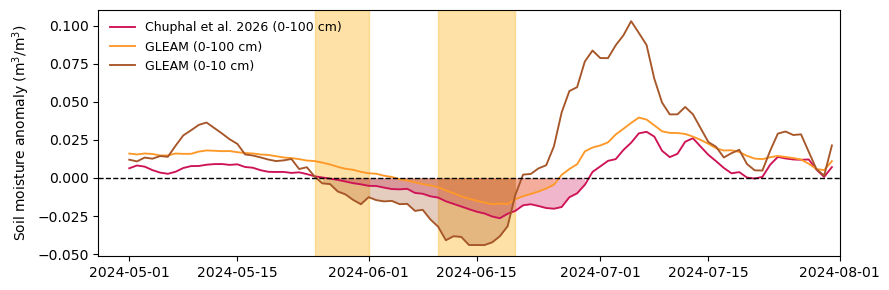

In [12]:
sets = [("Chuphal et al. 2026 (0-100 cm)", df_mean.sel(time="2024"),          df_mean_p10,           "#ce1256"),
        ("GLEAM (0-100 cm)",               df_gleam_mean.sel(time="2024"),    df_gleam_mean_p10,     "#fe9929"),
        ("GLEAM (0-10 cm)",                df_gleam_s_mean.sel(time="2024"),  df_gleam_s_mean_p10,   "#a65628"),]  

fig, ax = plt.subplots(figsize=(9, 3))
for name, o, c, col in sets:
    x, y = pd.to_datetime(o.time.values), np.asarray(o).squeeze()
    ax.plot(x, y, color=col, lw=1.35, label=f"{name} ")
    ax.fill_between(x, y, 0, where=y < 0, color=col, alpha=0.3, lw=0)
    
for i, (label, (start, end)) in enumerate(event_windows.items()):
    ax.axvspan(np.datetime64(start), np.datetime64(end),
               color='#fec44f', alpha=0.5, zorder=0)

ax.axhline(y=0, color='k',linestyle='--',lw=1)


ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.set_xlim(pd.Timestamp("2024-04-27"), pd.Timestamp("2024-08-01"))
ax.set_ylabel(r"Soil moisture anomaly (m$^3$/m$^3$)")                        

ax.legend(frameon=False, fontsize=9, ncol=1,loc='upper left')
plt.tight_layout()
plt.savefig("sm_verify.pdf",dpi=300,format='pdf',transparent=True)
plt.show()